# Ćwiczenie 5: Przekształcenia lokalne w analizie obrazów medycznych
## Część 1: Operacje w sąsiedztwie piksela i mechanizm splotu (Convolution)

### 1. Wstęp Teoretyczny
Do tej pory zajmowaliśmy się **przekształceniami punktowymi**. Wartość piksela na obrazie wyjściowym zależała wyłącznie od jego wartości na obrazie wejściowym (np. algorytmy okienkowania, transformacje logarytmiczne, poprawa kontrastu).

W **przekształceniach lokalnych** wartość piksela wyjściowego zależy od wartości piksela wejściowego **oraz jego najbliższego otoczenia** (sąsiedztwa). Analizujemy relacje przestrzenne między pikselami, co pozwala nam m.in. redukować szum lub uwydatniać krawędzie tkanek.

### 2. Splot (Convolution) i Maska (Kernel)
Podstawową operacją matematyczną w przekształceniach lokalnych jest **splot dyskretny**. Polega on na przesuwaniu okna (tzw. maski splotu lub kernela) po całej macierzy obrazu.

Matematycznie, dla obrazu $f$ i maski $h$ o wymiarach $(2k+1) \times (2k+1)$, wartość nowego piksela $g(x,y)$ wyraża się wzorem:

$$g(x,y) = \sum_{i=-k}^{k} \sum_{j=-k}^{k} h(i,j) \cdot f(x-i, y-j)$$

**Maska splotu** to mała macierz wag (najczęściej 3x3, 5x5). Aby obraz po operacji wygładzania nie stał się nienaturalnie jasny lub ciemny, suma wszystkich wag w masce dolnoprzepustowej powinna wynosić $1$.

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.patches import Rectangle
from IPython.display import HTML

# 1. Tworzymy mały obraz 6x6
image = np.zeros((6, 6), dtype=float)
image[1:5, 1:5] = 1.0
image[1, 4] = 0.5  # Zaszumiamy jeden piksel

# 2. Kernel uśredniający 3x3
kernel = np.ones((3, 3)) / 9.0

# 3. Przygotowanie figury do animacji
fig, (ax_img, ax_res) = plt.subplots(1, 2, figsize=(10, 5))
fig.suptitle('Animacja Splotu (Convolution)', fontsize=16)

ax_img.imshow(image, cmap='gray', vmin=0, vmax=1)
ax_img.set_title('Obraz wejściowy + Maska')
ax_img.set_xticks(np.arange(-0.5, 6, 1))
ax_img.set_yticks(np.arange(-0.5, 6, 1))
ax_img.grid(color='red', linestyle='-', linewidth=0.5)
ax_img.set_xticklabels([])
ax_img.set_yticklabels([])

result = np.zeros_like(image)
im_res = ax_res.imshow(result, cmap='gray', vmin=0, vmax=1)
ax_res.set_title('Obraz wynikowy')
ax_res.set_xticks(np.arange(-0.5, 6, 1))
ax_res.set_yticks(np.arange(-0.5, 6, 1))
ax_res.grid(color='blue', linestyle='-', linewidth=0.5)
ax_res.set_xticklabels([])
ax_res.set_yticklabels([])

mask_rect = Rectangle((-0.5, -0.5), 3, 3, fill=False, edgecolor='red', linewidth=3)
ax_img.add_patch(mask_rect)

target_rect = Rectangle((0.5, 0.5), 1, 1, fill=False, edgecolor='blue', linewidth=3)
ax_res.add_patch(target_rect)

calc_text = fig.text(0.5, 0.05, '', ha='center', fontsize=12)

frames = [(i, j) for i in range(1, 5) for j in range(1, 5)]

def update(frame):
    i, j = frame
    mask_rect.set_xy((j - 1.5, i - 1.5))
    target_rect.set_xy((j - 0.5, i - 0.5))
    
    region = image[i-1:i+2, j-1:j+2]
    conv_val = np.sum(region * kernel)
    result[i, j] = conv_val
    im_res.set_array(result)
    calc_text.set_text(f"Środek maski: ({i},{j}) -> Wartość splotu = {conv_val:.2f}")
    
    return [mask_rect, target_rect, im_res, calc_text]

ani = animation.FuncAnimation(fig, update, frames=frames, interval=800, blit=False, repeat=False)
plt.close(fig) 

# Wyświetlenie w Jupyter Notebook jako video HTML5
#HTML(ani.to_html5_video())
HTML(ani.to_jshtml())

### 3. Problem Brzegowy
Gdy środek maski znajduje się na krawędzi obrazu, część maski "wychodzi" poza macierz danych. W analizie medycznej najczęściej rozwiązuje się to poprzez **odbicie lustrzane (reflect)** lub **powielenie pikseli brzegowych (nearest)**, aby nie wprowadzać sztucznych, czarnych ramek (jak w przypadku wypełniania zerami).

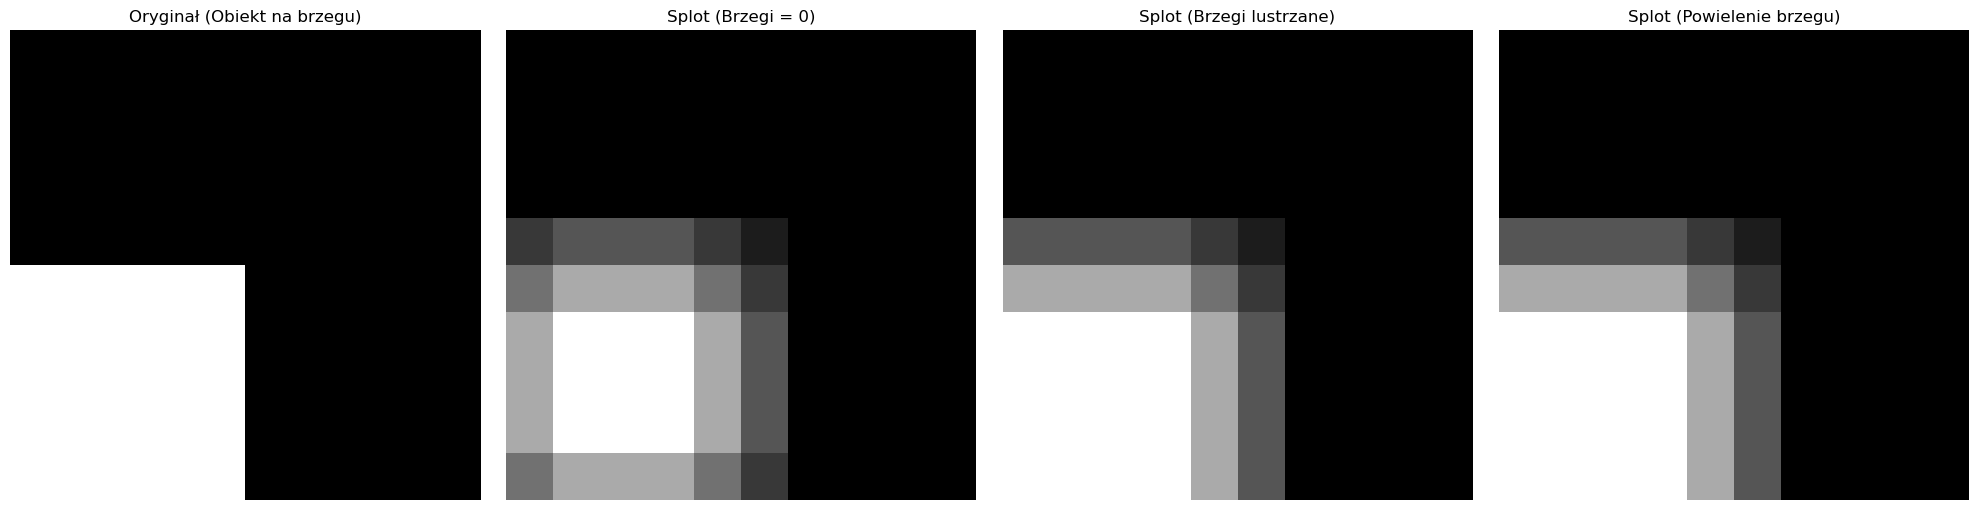

In [15]:
from scipy.ndimage import convolve
import numpy as np
import matplotlib.pyplot as plt

# Tworzymy obraz, gdzie jasny obiekt (1.0) leży na SAMYM BRZEGU macierzy
img_test = np.zeros((10, 10))
img_test[5:, 0:5] = 1.0  # Obiekt dotyka lewej i dolnej krawędzi!

kernel_3x3 = np.ones((3, 3)) / 9.0

# Splot z 3 różnymi warunkami brzegowymi
res_constant = convolve(img_test, kernel_3x3, mode='constant', cval=0.0)
res_reflect  = convolve(img_test, kernel_3x3, mode='reflect')
res_nearest  = convolve(img_test, kernel_3x3, mode='nearest')

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
axes[0].imshow(img_test, cmap='gray', vmin=0, vmax=1)
axes[0].set_title('Oryginał (Obiekt na brzegu)')

axes[1].imshow(res_constant, cmap='gray', vmin=0, vmax=1)
axes[1].set_title('Splot (Brzegi = 0)')

axes[2].imshow(res_reflect, cmap='gray', vmin=0, vmax=1)
axes[2].set_title('Splot (Brzegi lustrzane)')

axes[3].imshow(res_nearest, cmap='gray', vmin=0, vmax=1)
axes[3].set_title('Splot (Powielenie brzegu)')

for ax in axes: ax.axis('off')
plt.tight_layout()
plt.show()

**Wniosek:** Kiedy obiekt tkankowy leży na krawędzi skanu, wypełnienie zerami (constant) powoduje sztuczne przyciemnienie narządu przy brzegu obrazu, maskując jego fizyczną gęstość. Odbicie lustrzane (reflect) poprawnie uśrednia tkankę samą ze sobą na obrzeżach, zachowując jednolitą wartość matematyczną. Z tego powodu w radiologii stosuje się zazwyczaj to drugie rozwiązanie.